<a href="https://colab.research.google.com/github/elhamod/IS834_Fall_2026/blob/main/Session%2010%20-%20Unsupervised%20Learning%20and%20Clustering/Unsupervised_Learning_and_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IS834 — Session 10**

Work through this notebook in Colab. The lecture cells are filled in and ready to run; the
**Case** and the **Exercises** are yours to complete — write your code in the `# Your code here` cells and your
reasoning in the `*Provide your answer here*` cells.

Every dataset is read straight from the course repository, so there is nothing to upload or install.

*Adapted from Brock Tibert's IS834 Fall 2025 notebook `10_ML2_Supervised_and_Unsupervised.ipynb`. Edited for Fall 2026 by Mohannad Elhamod.*

# Session 10 — Unsupervised learning: clustering

**Learning goals**

1. What KMeans clustering does, and what it needs from your data
2. Standardising features, and why clustering is close to meaningless without it
3. Choosing *k* with the silhouette score
4. Judging when a clustering answers a business question and when it doesn't


## Setup

The clustering work below runs on the **bank** dataset — the same two files you joined in sessions 8 and 9. Run these cells first to rebuild it.


In [1]:
# Everything this notebook needs, imported once at the top.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Show wide tables without pandas truncating them to a handful of columns.
pd.set_option('display.max_columns', 100)

# Every data file this notebook uses is read straight from the course repository.
# There is nothing to upload: DATA is the folder those files live in.
DATA = "https://raw.githubusercontent.com/elhamod/IS834_Fall_2026/main/data/"

In [2]:
# Read the two bank files and join them back into one table on the customer id.
customers = pd.read_csv(DATA + "bank-customers.csv")
marketing = pd.read_csv(DATA + "bank-marketing.csv")

bank = pd.merge(customers, marketing, on="id", how="left")
print(bank.shape)
bank.info()


(45211, 18)
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         45211 non-null  str  
 1   age        45211 non-null  int64
 2   job        45211 non-null  str  
 3   marital    45211 non-null  str  
 4   education  45211 non-null  str  
 5   default    45211 non-null  str  
 6   balance    45211 non-null  int64
 7   housing    45211 non-null  str  
 8   loan       45211 non-null  str  
 9   contact    45211 non-null  str  
 10  day        45211 non-null  int64
 11  month      45211 non-null  str  
 12  duration   45211 non-null  int64
 13  campaign   45211 non-null  int64
 14  pdays      45211 non-null  int64
 15  previous   45211 non-null  int64
 16  poutcome   45211 non-null  str  
 17  y          45211 non-null  str  
dtypes: int64(7), str(11)
memory usage: 10.0 MB


### Bank marketing dataset overview

| **Attribute** | **Description** | **Type / Values** |
|----------------|-----------------|-------------------|
| **id** | The bank customer's id | String |
| **age** | Age of the client | Numeric |
| **job** | Type of job | Categorical: *admin.*, *unknown*, *unemployed*, *management*, *housemaid*, *entrepreneur*, *student*, *blue-collar*, *self-employed*, *retired*, *technician*, *services* |
| **marital** | Marital status | Categorical: *married*, *divorced*, *single* |
| **education** | Level of education | Categorical: *unknown*, *primary*, *secondary*, *tertiary* |
| **default** | Has credit in default? | Binary: *yes*, *no* |
| **balance** | Average yearly balance (in euros) | Numeric |
| **housing** | Has housing loan? | Binary: *yes*, *no* |
| **loan** | Has personal loan? | Binary: *yes*, *no* |
| **contact** | Contact communication type | Categorical: *unknown*, *telephone*, *cellular* |
| **day** | Last contact day of the month | Numeric |
| **month** | Last contact month of year | Categorical: *jan*, *feb*, ..., *dec* |
| **duration** | Last contact duration (in seconds) | Numeric |
| **campaign** | Number of contacts performed during this campaign (includes last contact) | Numeric |
| **pdays** | Days passed since client was last contacted (-1 = never contacted) | Numeric |
| **previous** | Number of contacts before this campaign | Numeric |
| **poutcome** | Outcome of previous marketing campaign | Categorical: *unknown*, *other*, *failure*, *success* |
| **y** | Client subscribed a term deposit? | Binary: *yes*, *no* |


## Clustering with KMeans

### What KMeans needs

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/c/c8/Cluster-2.svg/1200px-Cluster-2.svg.png"  height="300" width="420">

![](https://cdn-images-1.medium.com/max/1600/1*tWaaZX75oumVwBMcKN-eHA.png)

**Inputs.**

- a DataFrame of **numeric** columns, used to measure how similar two rows are
- the number of clusters we want, commonly called `k`

**Output.**

- a cluster number for each row of the DataFrame, from 0 to `k` − 1

KMeans measures the distance between rows, and you cannot take the distance between "married" and "single". So it only works on numeric columns.

In [3]:
# A few random rows, so we can see what we are clustering.
bank.sample(3, random_state=595)


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
25422,271fcf1c-7c13-4bee-8b46-954901f11896,31,admin.,married,secondary,no,355,yes,no,cellular,18,nov,530,1,193,1,failure,no
40762,43c41098-4644-4283-b677-5b07a45f5048,33,admin.,married,secondary,no,95,yes,no,cellular,10,aug,155,1,102,1,success,no
35978,bee262b6-cb8a-4f00-8e96-08416316d3e2,43,blue-collar,married,primary,no,60,no,no,cellular,8,may,487,2,367,2,other,no


In [4]:
# KMeans needs numbers, so keep only the numeric columns.
bank_numeric = bank.select_dtypes("number")
bank_numeric.head(3)

,age,balance,day,duration,campaign,pdays,previous
0,58,2143,5,261,1,-1,0
1,44,29,5,151,1,-1,0
2,33,2,5,76,1,-1,0


In [5]:
# Summary statistics -- compare the scales of the columns.
bank_numeric.describe().round(1)

,age,balance,day,duration,campaign,pdays,previous
count,45211.0,45211.0,45211.0,45211.0,45211.0,45211.0,45211.0
mean,40.9,1362.3,15.8,258.2,2.8,40.2,0.6
std,10.6,3044.8,8.3,257.5,3.1,100.1,2.3
min,18.0,-8019.0,1.0,0.0,1.0,-1.0,0.0
25%,33.0,72.0,8.0,103.0,1.0,-1.0,0.0
50%,39.0,448.0,16.0,180.0,2.0,-1.0,0.0
75%,48.0,1428.0,21.0,319.0,3.0,-1.0,0.0
max,95.0,102127.0,31.0,4918.0,63.0,871.0,275.0


**Question 1.** Compare the standard deviation of `balance` with the standard deviation of `campaign`. What is about to go wrong?


**Answer**

*Provide your answer here*

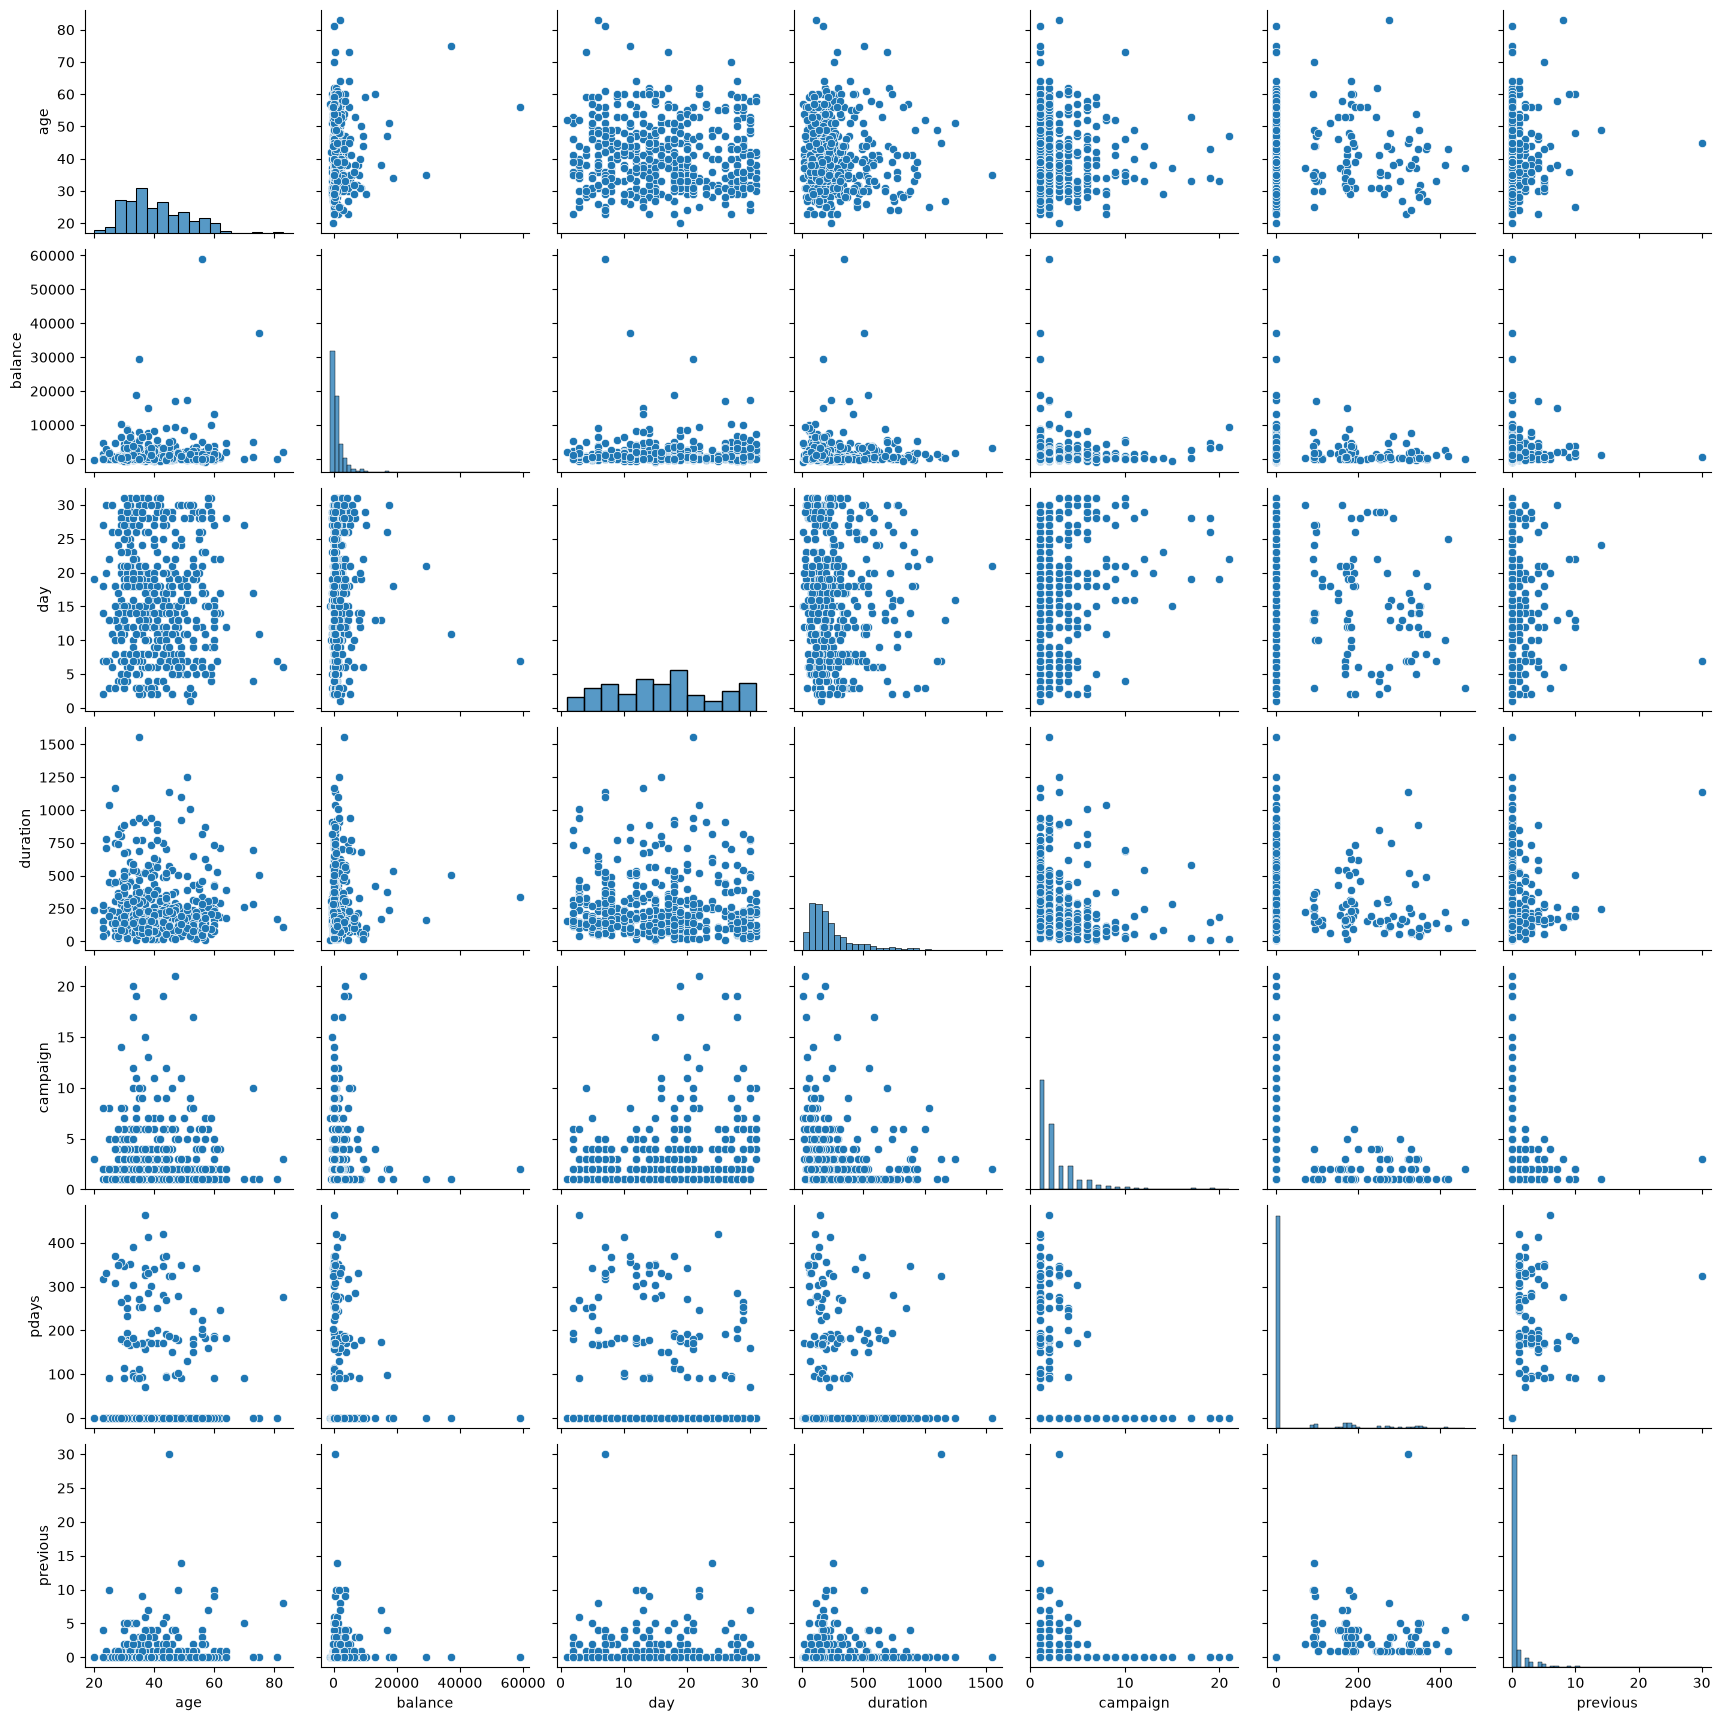

In [6]:
# seaborn's pairplot shows every pair of variables at once.
# 500 rows is a sample -- plotting all 45,211 points would be slow and unreadable.
sns.pairplot(bank_numeric.sample(500, random_state=595))
plt.show()


### First, the trap: clustering the raw numbers

Before we standardise anything, let us run KMeans exactly as it comes and look honestly at what it produces.


In [7]:
# Cluster the RAW columns -- deliberately skipping the standardisation step.
raw_kmeans = KMeans(n_clusters=3, random_state=595, n_init=10)
bank["cluster_raw"] = raw_kmeans.fit_predict(bank_numeric)

# The average of each variable inside each cluster, plus how many customers landed there.
raw_profile = bank.groupby("cluster_raw")[bank_numeric.columns.tolist()].mean().round(1)
raw_profile["n_customers"] = bank["cluster_raw"].value_counts().sort_index()
raw_profile


,age,balance,day,duration,campaign,pdays,previous,n_customers
cluster_raw,,,,,,,,
0,40.6,643.8,15.8,256.2,2.8,40.3,0.6,40567
1,45.6,25501.4,16.1,256.0,2.7,32.6,0.5,309
2,43.4,6365.0,16.1,276.6,2.7,39.9,0.7,4335


In [47]:
# bank_numeric
raw_profile = bank.groupby("cluster_raw").agg(n_customers=("cluster_raw", "count"),campaign=("campaign", "mean"),age=("age", "mean"),balance=("balance", "mean"),day=("day", "mean"),duration=("duration", "mean"),pdays=("pdays", "mean"),previous=("previous", "mean")).round(1)
raw_profile

,n_customers,campaign,age,balance,day,duration,pdays,previous
cluster_raw,,,,,,,,
0,40567,2.8,40.6,643.8,15.8,256.2,40.3,0.6
1,309,2.7,45.6,25501.4,16.1,256.0,32.6,0.5
2,4335,2.7,43.4,6365.0,16.1,276.6,39.9,0.7


**Question 2.** Read the table above. What did the algorithm actually group people by?


**Answer**

*Provide your answer here*

### The fix: standardise first

A **z-score** rewrites each value as "how many standard deviations from the mean of its own column". After the transformation every column has mean 0 and standard deviation 1, so no column can dominate by virtue of its units.


![](https://agitator.thedonorvoice.com/wp-content/uploads/2022/08/z-score-1024x756.png)


In [42]:
# StandardScaler converts every column to a z-score: (value - column mean) / column std.
scaler = StandardScaler()
bank_scaled = scaler.fit_transform(bank_numeric)

# fit_transform hands back a plain array, so wrap it in a DataFrame to inspect it.
# Every mean should now be 0 and every standard deviation 1.
bank_scaled_df = pd.DataFrame(bank_scaled, columns=bank_numeric.columns)
bank_scaled_df.describe().round(3)

,age,balance,day,duration,campaign,pdays,previous
count,45211.000,45211.000,45211.000,45211.000,45211.000,45211.000,45211.000
mean,0.000,0.000,0.000,0.000,0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.160,-3.081,-1.779,-1.002,-0.569,-0.411,-0.252
25%,-0.747,-0.424,-0.938,-0.603,-0.569,-0.411,-0.252
50%,-0.182,-0.300,0.023,-0.304,-0.247,-0.411,-0.252
75%,0.665,0.022,0.624,0.236,0.076,-0.411,-0.252
max,5.091,33.095,1.826,18.095,19.444,8.297,119.136


In [48]:
# Cluster the standardised data. k = 3 is a starting guess; we test it below.
kmeans = KMeans(n_clusters=3, random_state=595, n_init=10)
clusters = kmeans.fit_predict(bank_scaled)

# One cluster number per row, counting from zero.
print(clusters[:5])

[1 1 1 1 1]


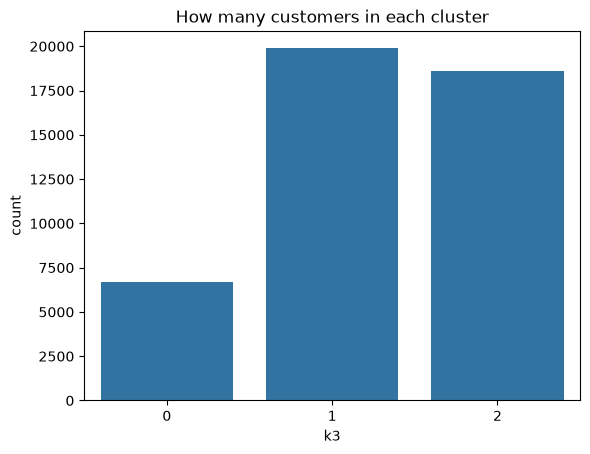

In [49]:
# Attach the assignment back onto the original dataframe so we can describe the groups.
bank["k3"] = clusters

sns.countplot(data=bank, x="k3")
plt.title("How many customers in each cluster")
plt.show()


### Describing the clusters

A cluster number is not an insight. To say anything useful you have to look at what is *typical* inside each group.

**Exercise 1.** Calculate the average of every numeric variable within each cluster, on both the original scale and the standardised scale, and describe the three groups in plain English.


In [ ]:
# Your code here -- the average of every numeric variable in each cluster, in the original units

In [ ]:
# Your code here -- the same averages on the standardised scale

**Answer**

*Provide your answer here*

### Choosing *k*

![](https://miro.medium.com/v2/resize:fit:720/1*ftfk97tHNG9pF25BRD8GsA.png)

The **silhouette score** is a popular way to judge a clustering. It ranges from +1 (ideal) to −1 (very bad).

- Every row gets a score: how close it is to the rows in its own cluster, balanced against how far it is from the nearest other cluster.
- The row scores are averaged into one number for the whole solution.
- In business terms: each cluster should be compact, and clearly different from the others.

To choose *k*, fit a model for each candidate value, score it, and plot the scores.

k = 2   silhouette = 0.337
k = 3   silhouette = 0.188
k = 4   silhouette = 0.196
k = 5   silhouette = 0.210
k = 6   silhouette = 0.207
k = 7   silhouette = 0.215
k = 8   silhouette = 0.225
k = 9   silhouette = 0.234


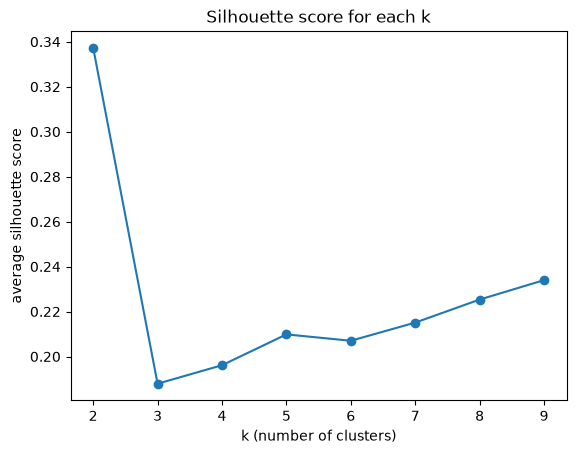

In [50]:
# Fit and score a model for each k from 2 to 9.
# A 2,000-row sample keeps this fast enough to run in class; the pattern holds on the full data.
sample_scaled = pd.DataFrame(bank_scaled, columns=bank_numeric.columns).sample(2000, random_state=595)

scores = []
for k in range(2, 10):
    trial = KMeans(n_clusters=k, random_state=595, n_init=10)
    labels = trial.fit_predict(sample_scaled)
    scores.append(silhouette_score(sample_scaled, labels))
    print(f"k = {k}   silhouette = {scores[-1]:.3f}")

plt.plot(range(2, 10), scores, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("average silhouette score")
plt.title("Silhouette score for each k")
plt.show()

**Question 3.** The silhouette score is highest at k = 2, but we have been working with k = 3. Should we switch?


**Answer**

*Provide your answer here*

### Case: segmenting cars

**In-class exercise.** You are working as a data analyst for a new auto consulting firm that helps car manufacturers position their vehicles more effectively in the market. The firm has collected data on car specifications, performance metrics, and prices from multiple brands. Your task is to use clustering to identify natural groupings of cars—such as economy, mid-range, and luxury segments—based on their technical and performance attributes. These clusters will help the marketing team understand how cars differ across brands and which features distinguish higher-end vehicles from budget-friendly models.

**Tips.**

- Choose the features for this task yourself, rather than using the full dataset. That is part of being an analyst!
- Should you include price?
- Break the task into small code cells. Run each one, review its output, and ask whether the step is really needed.

#### The cars dataset

| # | Feature | Description | Type |
|---|----------|--------------|------|
| 1 | Car_ID | Unique ID of each observation | Integer |
| 2 | Symboling | Assigned insurance risk rating; +3 = risky, -3 = safe | Categorical |
| 3 | carCompany | Name of the car company | Categorical |
| 4 | fueltype | Type of fuel used (gas or diesel) | Categorical |
| 5 | aspiration | Aspiration type used in the car | Categorical |
| 6 | doornumber | Number of doors in the car | Categorical |
| 7 | carbody | Body style of the car | Categorical |
| 8 | drivewheel | Type of drive wheel | Categorical |
| 9 | enginelocation | Location of the engine | Categorical |
| 10 | wheelbase | Wheelbase of the car | Numeric |
| 11 | carlength | Length of the car | Numeric |
| 12 | carwidth | Width of the car | Numeric |
| 13 | carheight | Height of the car | Numeric |
| 14 | curbweight | Weight of the car without occupants or baggage | Numeric |
| 15 | enginetype | Type of engine | Categorical |
| 16 | cylindernumber | Number of cylinders in the car | Categorical |
| 17 | enginesize | Engine size | Numeric |
| 18 | fuelsystem | Type of fuel system | Categorical |
| 19 | boreratio | Bore ratio of the engine | Numeric |
| 20 | stroke | Stroke or engine volume | Numeric |
| 21 | compressionratio | Compression ratio of the car | Numeric |
| 22 | horsepower | Horsepower | Numeric |
| 23 | peakrpm | Peak revolutions per minute (RPM) | Numeric |
| 24 | citympg | Mileage in the city | Numeric |
| 25 | highwaympg | Mileage on the highway | Numeric |
| 26 | price | Price of the car *(Dependent variable)* | Numeric |

#### Step 1 — load the data and look at it


In [280]:
# Your code here -- load cars.csv into a DataFrame called cars and look at it
cars = pd.read_csv(DATA + "cars.csv")
print(cars.shape, '\n')
cars.info()

(205, 26) 

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 

In [281]:
cars.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [282]:
# Your code here -- which columns are numeric, and are any values missing?
cars_numeric = cars.select_dtypes("number")
cars_numeric.head()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0


#### Step 2 — choose features

**Question 4.** The task asks for groups based on *technical and performance attributes*. Which columns belong in the clustering, and should `price` be one of them?

**Answer**

*Provide your answer here*

In [283]:
# Your code here -- choose the clustering features

features = ["wheelbase", "carlength", "carwidth", "curbweight",
            "enginesize", "horsepower", "citympg", "highwaympg"]

X = cars_numeric[features]
X.head()


,wheelbase,carlength,carwidth,curbweight,enginesize,horsepower,citympg,highwaympg
0,88.6,168.8,64.1,2548,130,111,21,27
1,88.6,168.8,64.1,2548,130,111,21,27
2,94.5,171.2,65.5,2823,152,154,19,26
3,99.8,176.6,66.2,2337,109,102,24,30
4,99.4,176.6,66.4,2824,136,115,18,22


#### Step 3 — standardise, then choose *k*

Same trap as the bank data: `curbweight` runs into the thousands and `citympg` into the tens, so without standardising the clusters would just be "heavy, medium, light".


In [284]:
# Your code here -- standardise the features and score a range of k

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for k in range(2, 10):
    labels = KMeans(n_clusters=k, random_state=595, n_init=10).fit_predict(X_scaled)
    print(f'k = {k}     silhouette = {round(silhouette_score(X_scaled, labels), 3)}')


k = 2     silhouette = 0.452
k = 3     silhouette = 0.356
k = 4     silhouette = 0.341
k = 5     silhouette = 0.365
k = 6     silhouette = 0.351
k = 7     silhouette = 0.344
k = 8     silhouette = 0.296
k = 9     silhouette = 0.323


In [292]:
# Fit and score a model for each k from 2 to 9.
# A 2,000-row sample keeps this fast enough to run in class; the pattern holds on the full data.

scaler = StandardScaler()
cars_scaled = scaler.fit_transform(cars_numeric)

cars_sample = pd.DataFrame(cars_scaled, columns=cars_numeric.columns).sample(2000, random_state=595)

# sample_scaled = pd.DataFrame(bank_scaled, columns=bank_numeric.columns).sample(2000, random_state=595)

# scores = []
# for k in range(2, 10):
#     trial = KMeans(n_clusters=k, random_state=595, n_init=10)
#     labels = trial.fit_predict(cars_sample)
#     scores.append(silhouette_score(cars_sample, labels))
#     print(f"k = {k}   silhouette = {scores[-1]:.3f}")

# plt.plot(range(2, 10), scores, marker="o")
# plt.xlabel("k (number of clusters)")
# plt.ylabel("average silhouette score")
# plt.title("Silhouette score for each k")
# plt.show()

ValueError: Cannot take a larger sample than population when 'replace=False'

In [226]:
# cars["k2"] = KMeans(n_clusters=2, random_state=595, n_init=10).fit_predict(X_scaled)
# cars.groupby("k2")[features + ["price"]].mean().round(2)


,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,k2,price
k2,,,,,,,,,,,,,,,,,
0,0.63,103.82,185.77,68.04,54.55,3133.25,166.37,3.54,3.29,10.36,142.36,5060.27,19.44,24.49,21108.42,0.0,21108.42
1,0.95,95.96,167.57,64.73,53.27,2236.09,105.08,3.21,3.23,10.02,82.97,5160.98,28.42,34.21,8945.54,1.0,8945.54


**Question 5.** Which *k* should the case use?

**Answer**

*Provide your answer here*

In [256]:
# Your code here -- fit the segments and attach the labels to the cars table

kmeans = KMeans(n_clusters=3, random_state=595, n_init=10)
cars_numeric["segment"] = kmeans.fit_predict(X_scaled)
cars_numeric["segment"].value_counts().sort_index()   # 0: 62, 1: 52, 2: 91

segment
0    62
1    52
2    91
Name: count, dtype: int64

#### Step 4 — profile the segments and name them

**Question 6.** Name the three segments. Do they differ on price, which the clustering never saw?

In [257]:
# Your code here -- profile each segment, with price added back as a check
cars_numeric.groupby("segment")[features + ["price"]].mean().round(2)


,wheelbase,carlength,carwidth,curbweight,enginesize,horsepower,citympg,highwaympg,price
segment,,,,,,,,,
0,94.45,161.94,64.06,2029.87,94.74,67.27,32.89,38.69,7183.79
1,106.61,189.50,68.79,3267.04,172.31,142.12,19.46,23.96,22025.57
2,97.20,173.47,65.52,2507.18,122.88,107.51,23.29,29.22,12428.58


In [259]:
# Your code here -- name the segments
cars_numeric['segment_name'] = cars_numeric.segment.map({0: "Economy", 1: "Premium", 2: "Mid-range"})
cars_numeric.head()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,segment,segment_name
0,1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0,2,Mid-range
1,2,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0,2,Mid-range
2,3,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0,2,Mid-range
3,4,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0,2,Mid-range
4,5,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0,2,Mid-range


In [261]:
# Your code here -- cross-check the segments against columns you did not cluster on

for col in cars.select_dtypes("object").columns[1:]:
    # print(col)
    print(pd.crosstab(cars_numeric["segment_name"], cars[col], normalize="index").mul(100).round(0))
    print()

fueltype      diesel   gas
segment_name              
Economy         13.0  87.0
Mid-range        2.0  98.0
Premium         19.0  81.0

aspiration     std  turbo
segment_name             
Economy       97.0    3.0
Mid-range     82.0   18.0
Premium       63.0   37.0

doornumber    four   two
segment_name            
Economy       50.0  50.0
Mid-range     48.0  52.0
Premium       77.0  23.0

carbody       convertible  hardtop  hatchback  sedan  wagon
segment_name                                               
Economy               0.0      2.0       47.0   44.0    8.0
Mid-range             5.0      5.0       37.0   42.0   10.0
Premium               2.0      4.0       13.0   60.0   21.0

drivewheel    4wd   fwd   rwd
segment_name                 
Economy       3.0  94.0   3.0
Mid-range     7.0  62.0  32.0
Premium       2.0  12.0  87.0

enginelocation  front  rear
segment_name               
Economy         100.0   0.0
Mid-range        97.0   3.0
Premium         100.0   0.0

enginetype    

C:\Users\sanda\AppData\Local\Temp\ipykernel_330964\2593320091.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in cars.select_dtypes("object").columns[1:]:


<Axes: xlabel='enginesize', ylabel='horsepower'>

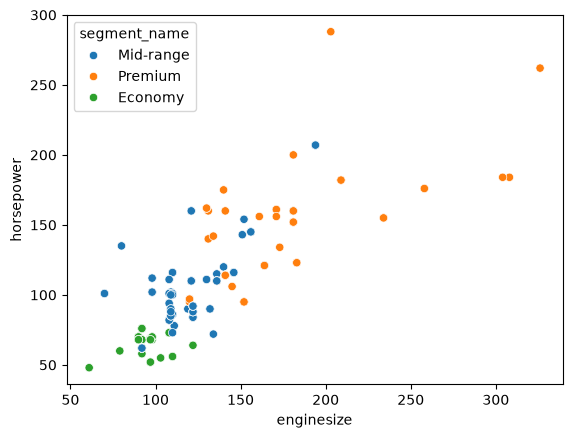

In [262]:
# Your code here -- plot two of the clustering variables, coloured by segment
sns.scatterplot(data=cars_numeric, x="enginesize", y="horsepower", hue="segment_name")


**Answer**

*Provide your answer here*

**Exercise 2.** The code below is meant to reproduce the three car segments. Run it. It runs without error, but it produces a different, worse answer. Find the bug.

In [ ]:
# Fit three segments on the car specifications and profile them.
spec_features = ["wheelbase", "carlength", "carwidth", "curbweight",
                 "enginesize", "horsepower", "citympg", "highwaympg"]
cars_specs = cars[spec_features]

wrong_kmeans = KMeans(n_clusters=3, random_state=595, n_init=10)
cars["segment_wrong"] = wrong_kmeans.fit_predict(cars_specs)

cars.groupby("segment_wrong")[spec_features + ["price"]].mean().round(1)

**Answer**

*Provide your answer here*

### Follow up Questions and Exercises


**Question 1.** Supervised learning has a test set to tell you whether the model is any good. Clustering has no labels at all. So how do you know a clustering is right?


**Answer**

*Provide your answer here*

**Question 2.** Your manager asks for "the customer segments" and wants five of them, because the team has five campaign budgets. The silhouette scores say two. What do you do?


**Answer**

*Provide your answer here*

**Exercise 1.** Re-run the bank clustering using only the variables that describe the customer — age and balance — and leave out the campaign-mechanics columns (`day`, `duration`, `campaign`, `pdays`, `previous`). Does it produce a more useful segmentation?


In [ ]:
# Your code here

**Answer**

*Provide your answer here*

## What comes next

Session 11 changes where the data comes from: instead of reading CSV files, you pull two tables out of a database with SQL, join them, and cluster the result with exactly today's recipe — numeric columns, standardise, fit, profile.

**Optional reading.** Linear regression for effect sizes, and statistical tests of the differences between clusters, are in `Optional/Supplemental_Statistics.ipynb`. That material is not examinable.